# Quatro geradores: pseudocódigos e diagramas

## Resumo

Este notebook reúne os algoritmos implementados para amostrar mecanismos e gerar trajetórias: AST original, contração pela Jacobiana, adaptação de Shao–Wu e parametrização VAR de Heaps. Cada imagem mostra a sequência completa; vermelho identifica etapas acrescentadas ou modificadas em relação à AST original. O [notebook 6](6_stability_methods_tradeoff.ipynb) apresenta as medidas executadas de explosão, baixa amplitude e velocidade.

As figuras são desenhadas a partir de texto versionado em [generator_algorithms.py](../../../src/tsfmxai/visualization/generator_algorithms.py). As equações e certificados permanecem na biblioteca; aqui mostramos seu fluxo de execução.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import subprocess
import sys
import time
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / "src" / "tsfmxai").exists())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from tsfmxai.visualization.generator_algorithms import ALGORITHMS, plot_generator_algorithm

METHODS = ("original", "jacobian", "shao-wu", "heaps-var")
assert tuple(ALGORITHMS) == METHODS
render_seconds = {}
print("Quatro diagramas; o desenho é determinístico e permanece incorporado ao notebook.")

Quatro diagramas; o desenho é determinístico e permanece incorporado ao notebook.


**O que foi feito.** Carregamos os quatro algoritmos atuais e fixamos sua ordem de apresentação.

## 1. AST original

Amostra forma binária com pesos de Catalan, operadores ADD/MULTIPLY, fontes, lags e coeficientes. O binding numérico fica separado da estrutura. Cada trajetória recebe histórico uniforme e inovações gaussianas independentes. A execução registra o primeiro valor que excede o limiar operacional ou deixa de ser finito.

Implementação: [random_expression.py](../../../src/tsfmxai/generators/random_expression.py), [trajectory.py](../../../src/tsfmxai/generators/trajectory.py). Na comparação, [stochastic.py](../../../src/tsfmxai/generators/stochastic.py) fornece o mesmo avaliador passo a passo aos quatro métodos.

<pre>
1. Derivar semente a partir de root_seed e índice do mecanismo.
2. Sortear quantidade de operadores, folhas e forma binária.
3. Canonicalizar a árvore e sortear coeficientes/lags.
4. Sortear histórico inicial uniforme.
5. Executar a AST recursivamente, acrescentando inovação gaussiana.
6. Registrar trajetória e primeiro cruzamento do limiar operacional.
</pre>

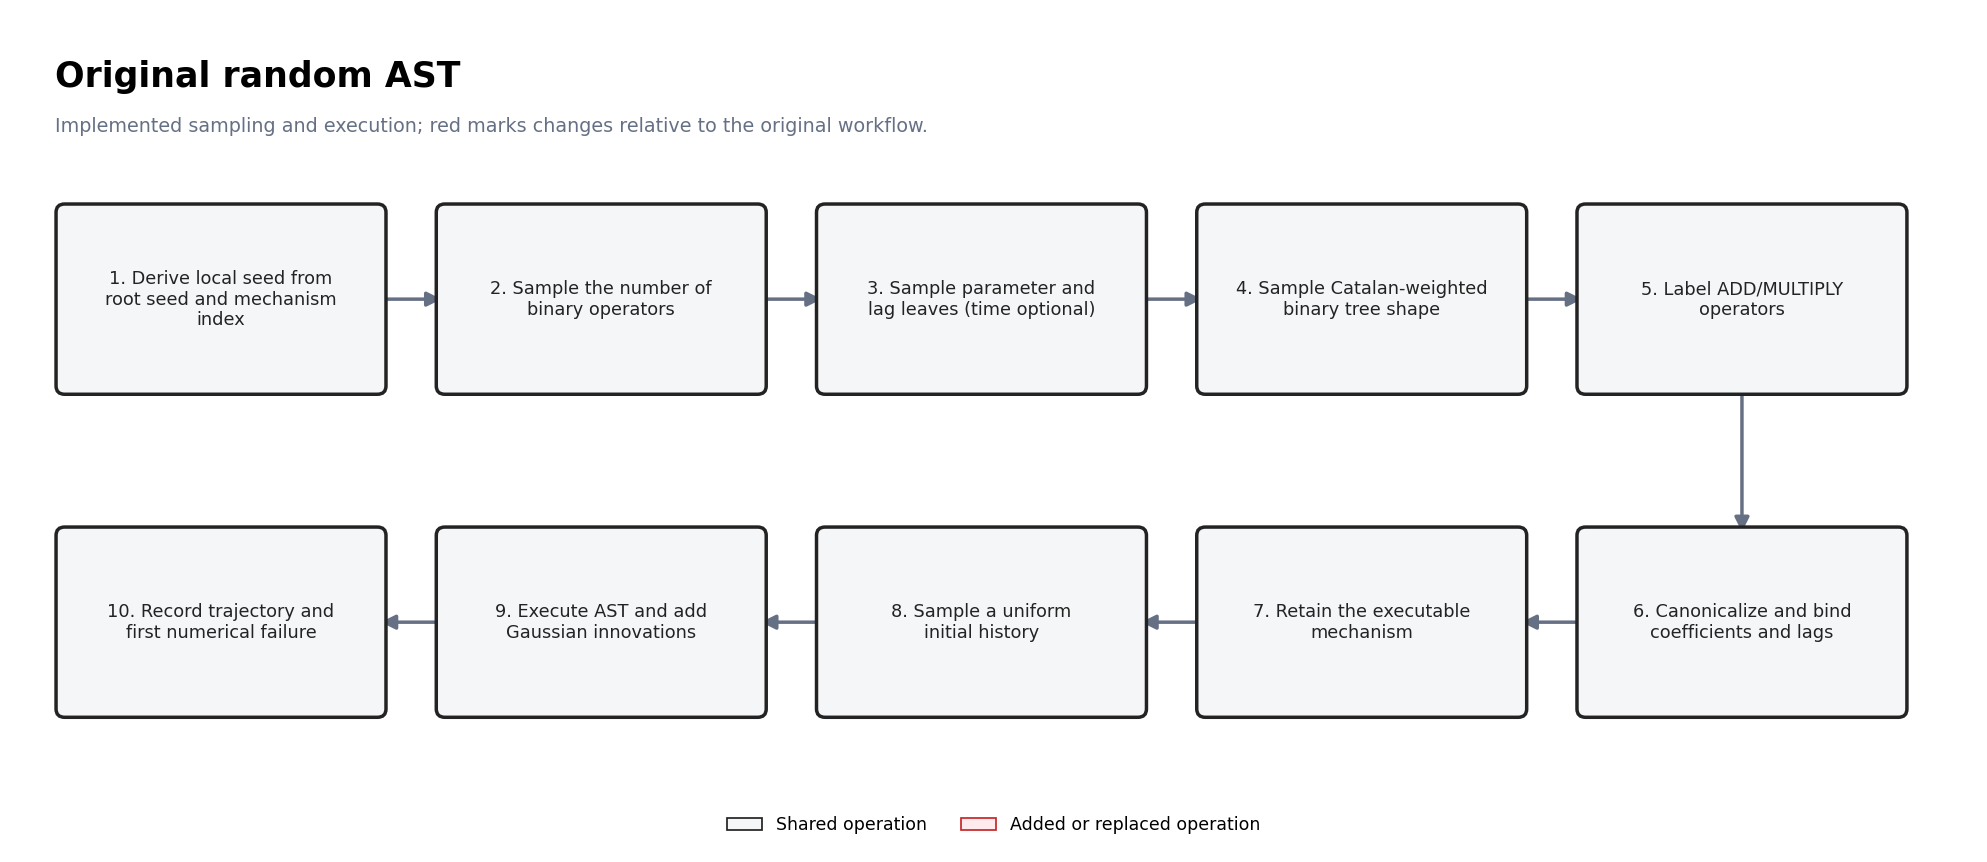

In [2]:
started = time.perf_counter()
figure = plot_generator_algorithm("original")
render_seconds["original"] = time.perf_counter() - started
plt.show()
plt.close(figure)

**O que foi feito.** A imagem percorre a linha superior da esquerda para a direita e retorna pela linha inferior. As etapas vermelhas identificam mudanças em relação ao fluxo original.

## 2. Contração pela Jacobiana

Os coeficientes nos lags são uma etapa interna configurada deste método. A aritmética intervalar limita a amplitude e as derivadas no domínio. O certificado inclui as linhas de deslocamento dos lags no estado aumentado. Uma escala comum atende ao limite de contração e à invariância da caixa com inovação uniforme limitada.

Implementação: [contraction.py](../../../src/tsfmxai/generators/contraction.py); [pseudocódigo detalhado](contraction_by_construction/PSEUDOCODE.md). O histórico uniforme inicia dentro da caixa; a contração controla o esquecimento das condições iniciais.

<pre>
1. Derivar semente e sortear árvore/bindings.
<span style="color:#c62828">2. Aplicar os coeficientes de lag configurados.</span>
<span style="color:#c62828">3. Propagar intervalos e derivadas na caixa do estado aumentado.</span>
<span style="color:#c62828">4. Incluir deslocamentos de lag na norma ponderada da Jacobiana.</span>
<span style="color:#c62828">5. Escalar para satisfazer contração e invariância com ruído.</span>
<span style="color:#c62828">6. Inicializar dentro da caixa; usar inovação uniforme limitada.</span>
<span style="color:#c62828">7. Executar a AST e verificar a permanência no domínio.</span>
</pre>

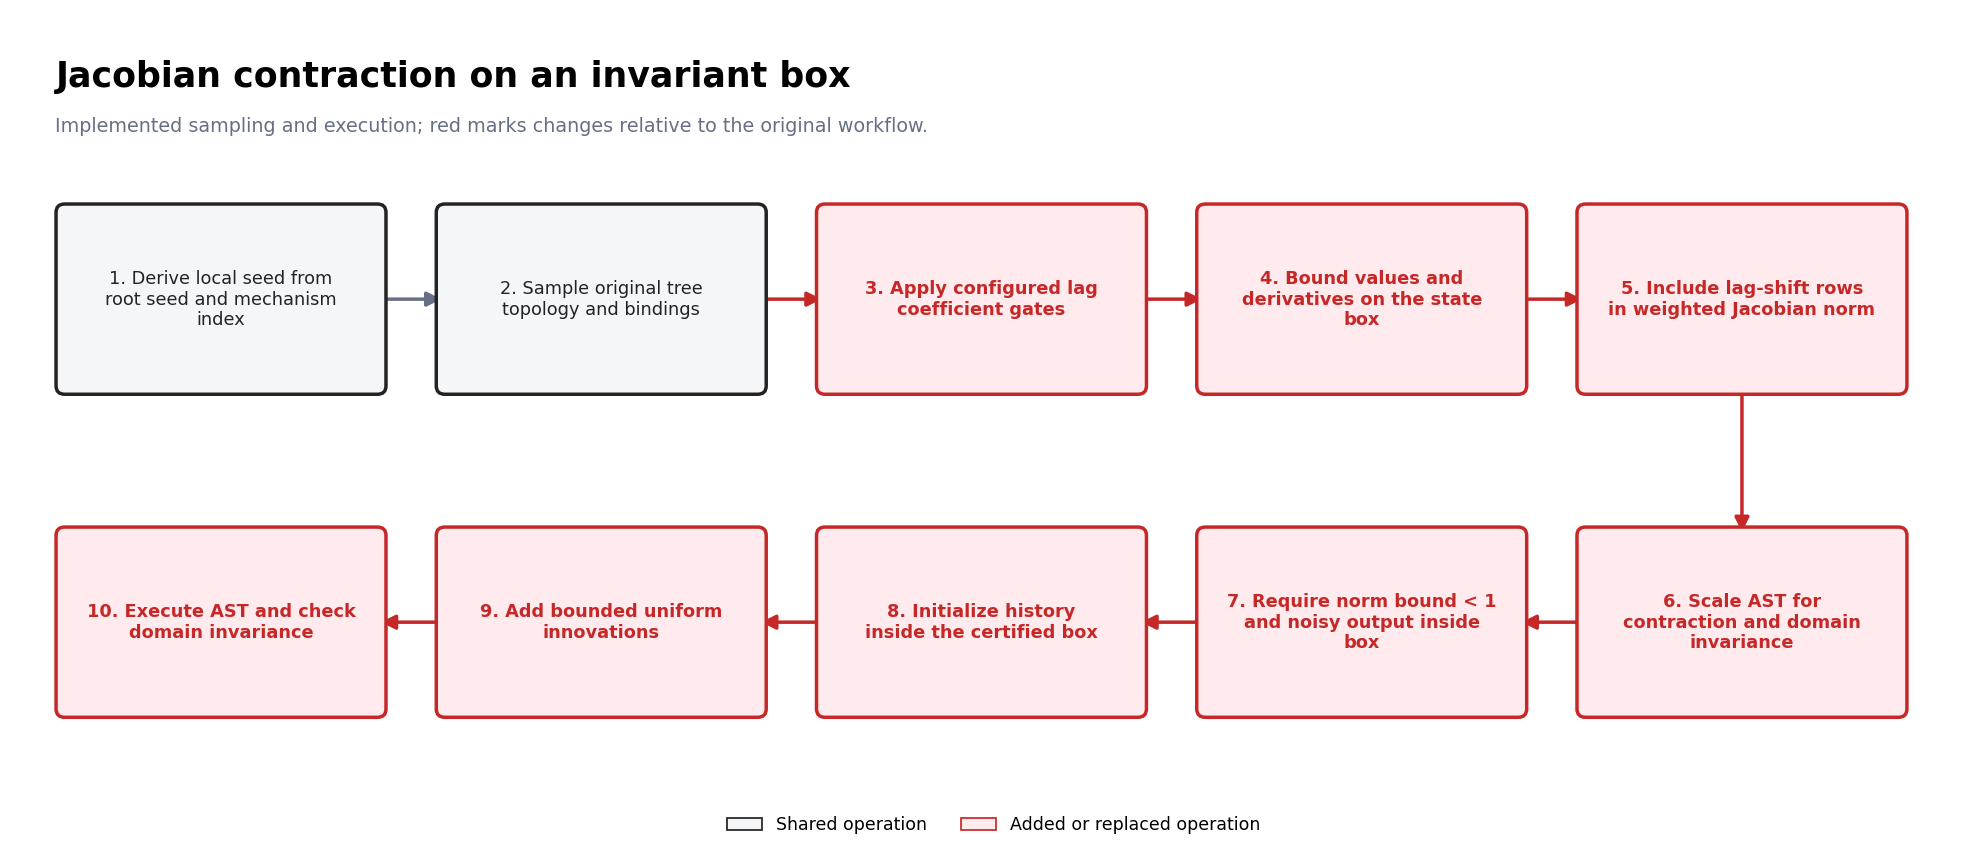

In [3]:
started = time.perf_counter()
figure = plot_generator_algorithm("jacobian")
render_seconds["jacobian"] = time.perf_counter() - started
plt.show()
plt.close(figure)

**O que foi feito.** A imagem percorre a linha superior da esquerda para a direita e retorna pela linha inferior. As etapas vermelhas identificam mudanças em relação ao fluxo original.

## 3. Shao–Wu: contração global em momentos

A adaptação usa somas e produtos de folhas TANH(LAG), de modo que valores e derivadas tenham limites globais. A soma das normas dos blocos de derivadas por lag é reduzida para menos de 1. Inovações gaussianas têm segundo momento finito. O histórico inicial é sorteado diretamente de uma distribuição uniforme; a trajetória finita pode ter um transiente.

Fundamentação: [Shao e Wu (2007), Teorema 5.1, pp. 11–12](https://arxiv.org/pdf/math/0611029#page=11). Gramática e inicialização são adaptações do projeto. Código: [shao_wu.py](../../../src/tsfmxai/generators/shao_wu.py); [experimento executado](shao_wu_gmc/00_global_moment_contraction.ipynb).

<pre>
1. Derivar semente e sortear uma árvore/binding por variável.
<span style="color:#c62828">2. Envolver cada folha LAG em TANH.</span>
<span style="color:#c62828">3. Propagar limites globais de amplitude e derivadas.</span>
<span style="color:#c62828">4. Escalar todas as equações para sum_l ||D_l||_2 &lt; 1.</span>
<span style="color:#c62828">5. Registrar as cotas de drift, ruído e ganhos por lag.</span>
<span style="color:#c62828">6. Sortear diretamente o histórico inicial uniforme.</span>
7. Executar as ASTs com inovações futuras independentes.
</pre>

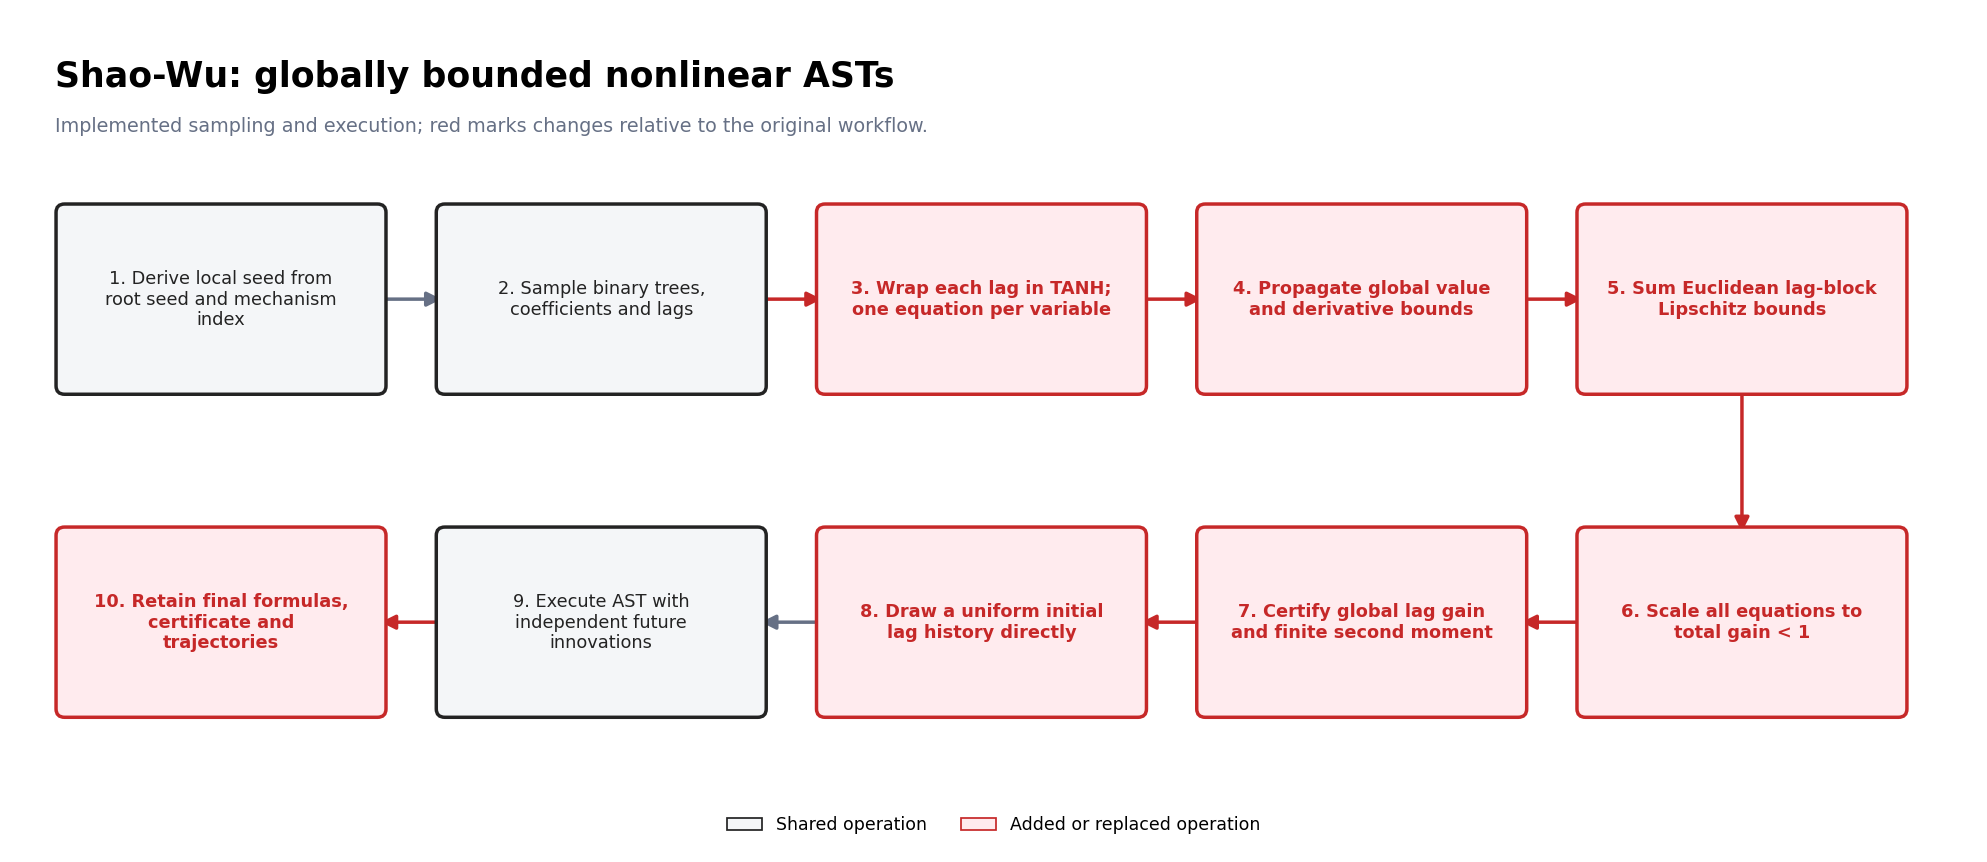

In [4]:
started = time.perf_counter()
figure = plot_generator_algorithm("shao-wu")
render_seconds["shao-wu"] = time.perf_counter() - started
plt.show()
plt.close(figure)

**O que foi feito.** A imagem percorre a linha superior da esquerda para a direita e retorna pela linha inferior. As etapas vermelhas identificam mudanças em relação ao fluxo original.

## 4. Heaps: VAR(p) estacionário

Amostramos matrizes livres, mapeamos seus valores singulares para autocorrelações parciais admissíveis e executamos as recursões com raízes quadradas simétricas. Os coeficientes VAR finais são armazenados como ASTs lineares. O histórico completo é sorteado da distribuição gaussiana estacionária conjunta e as inovações futuras são independentes.

Fundamentação: [Heaps (2023), Apêndice pp. 11–12](https://arxiv.org/pdf/2004.09455#page=11), [suplemento S1.3, pp. 7–8](https://arxiv.org/src/2004.09455v3/anc/supplMat.pdf). A lei de amostragem das matrizes livres é uma escolha do projeto. Código: [heaps.py](../../../src/tsfmxai/generators/heaps.py); [experimento executado](heaps_stationary_var/00_symmetric_var_generation.ipynb).

<pre>
1. Derivar semente local.
<span style="color:#c62828">2. Sortear ordem p e matrizes livres U_l.</span>
<span style="color:#c62828">3. Mapear U_l para autocorrelações parciais P_l.</span>
<span style="color:#c62828">4. Reconstruir covariâncias e coeficientes pelas recursões simétricas.</span>
<span style="color:#c62828">5. Verificar raio espectral, covariância e resíduo de Lyapunov.</span>
<span style="color:#c62828">6. Armazenar ASTs lineares e sortear histórico estacionário conjunto.</span>
7. Executar as ASTs com inovação gaussiana.
</pre>

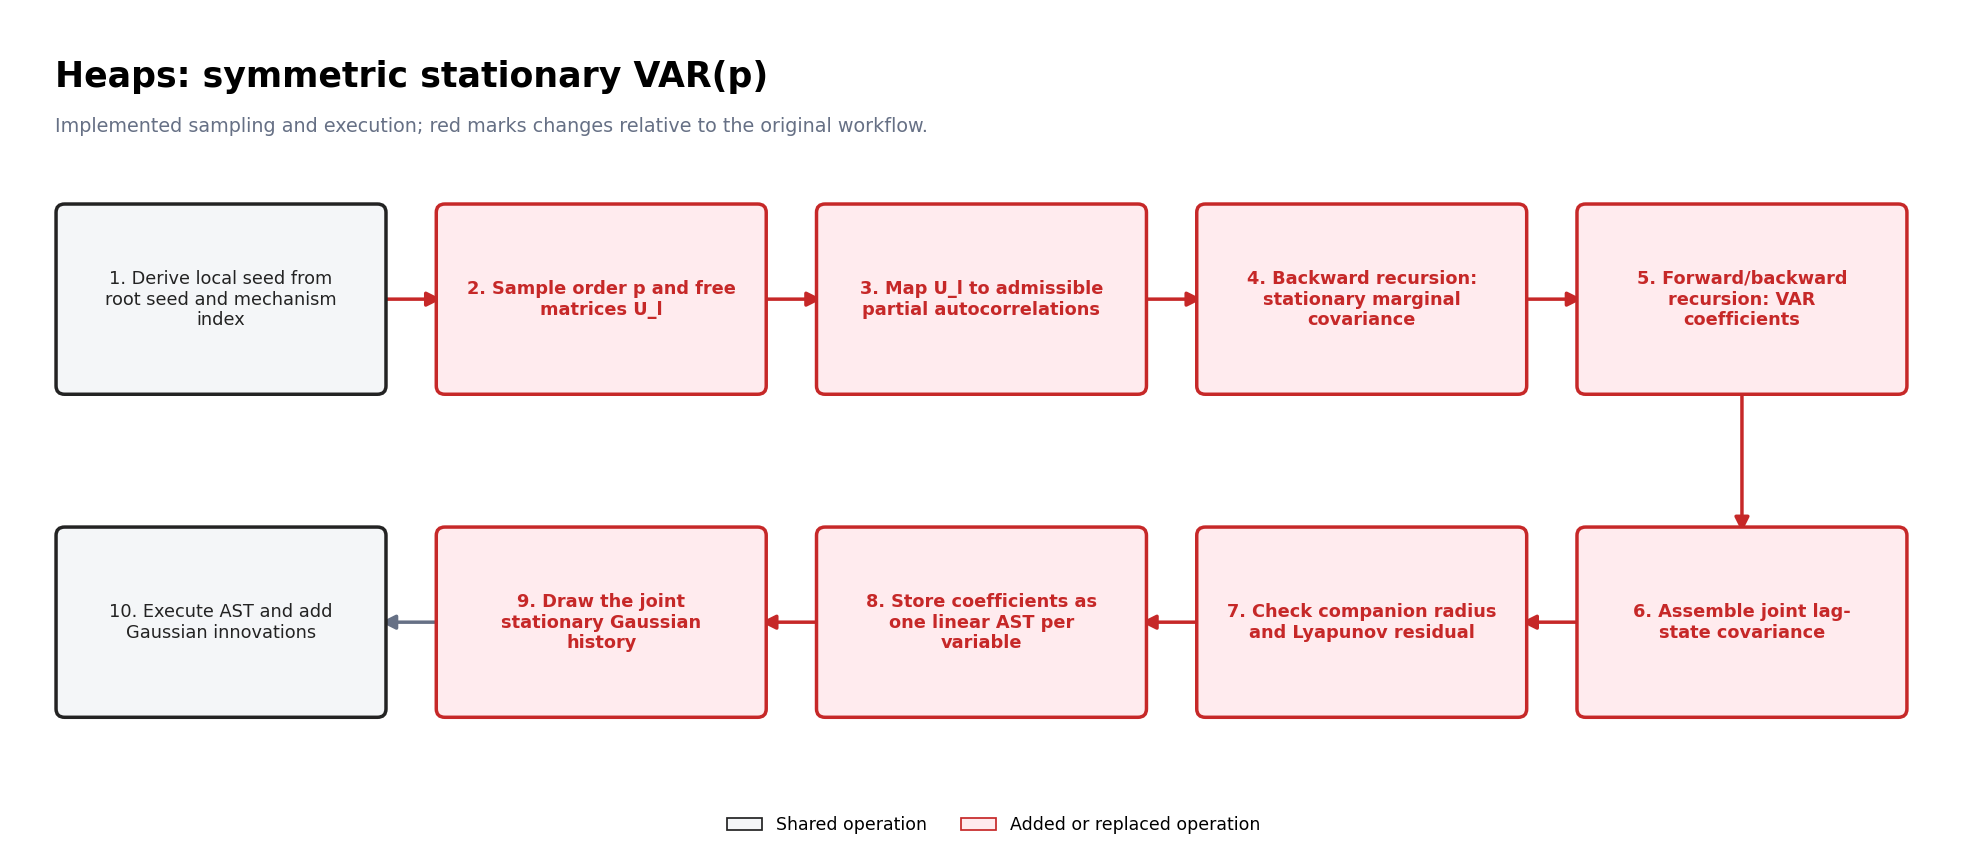

In [5]:
started = time.perf_counter()
figure = plot_generator_algorithm("heaps-var")
render_seconds["heaps-var"] = time.perf_counter() - started
plt.show()
plt.close(figure)

**O que foi feito.** A imagem percorre a linha superior da esquerda para a direita e retorna pela linha inferior. As etapas vermelhas identificam mudanças em relação ao fluxo original.

## Registro completo do experimento visual

Configuração, proveniência, verificações e reprodução permanecem nesta célula. Os tempos abaixo medem o desenho; as velocidades de geração estão no notebook 6.

In [6]:
source_paths = [
    "src/tsfmxai/visualization/generator_algorithms.py",
    "src/tsfmxai/generators/random_expression.py",
    "src/tsfmxai/generators/stochastic.py",
    "src/tsfmxai/generators/contraction.py",
    "src/tsfmxai/generators/shao_wu.py",
    "src/tsfmxai/generators/heaps.py",
]
record = {
    "experiment_id": "four_generator_pseudocode_diagrams",
    "status": "executed",
    "research_question": "Quais etapas distinguem os quatro geradores implementados?",
    "hypothesis": "Quatro diagramas com o mesmo formato tornam explícitas as diferenças de construção e execução.",
    "configuration": {"methods": METHODS, "steps_per_method": 10, "color_changes": "#c62828",
                      "figure_inches": [16, 7], "dpi": 125},
    "seeds": {"drawing": None, "reason": "Deterministic text and layout; no sampling.",
              "linked_generation_comparison_root_seed": 20261001},
    "provenance": {
        "git_head": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, text=True).strip(),
        "dirty_worktree": bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=PROJECT_ROOT, text=True).strip()),
        "source_sha256": {name: hashlib.sha256((PROJECT_ROOT / name).read_bytes()).hexdigest()
                          for name in source_paths},
        "python": sys.version, "platform": platform.platform(),
        "matplotlib": importlib.metadata.version("matplotlib"),
    },
    "metrics": {"diagram_count": len(METHODS), "render_seconds": render_seconds,
                "steps_per_method": {key: len(ALGORITHMS[key][1]) for key in METHODS},
                "changed_steps": {key: sum(changed for _, changed in ALGORITHMS[key][1]) for key in METHODS}},
    "scientific_summary": [
        "Original: sampled polynomial lagged recurrence and Gaussian innovations.",
        "Jacobian: weighted augmented-state contraction, invariant box and bounded innovations.",
        "Shao-Wu adaptation: bounded nonlinear drift, global lag gains and direct uniform history initialization.",
        "Heaps adaptation: symmetric VAR reparameterization and joint stationary Gaussian initialization.",
    ],
    "reproduction_command": ".\\.venv\\Scripts\\python.exe -m jupyter nbconvert --to notebook --execute --inplace experiments/abstract_syntax_tree/7_generator_pseudocode_diagrams.ipynb",
}
assert record["metrics"]["diagram_count"] == 4
assert all(count == 10 for count in record["metrics"]["steps_per_method"].values())
print(json.dumps(record, indent=2, ensure_ascii=False))

{
  "experiment_id": "four_generator_pseudocode_diagrams",
  "status": "executed",
  "research_question": "Quais etapas distinguem os quatro geradores implementados?",
  "hypothesis": "Quatro diagramas com o mesmo formato tornam explícitas as diferenças de construção e execução.",
  "configuration": {
    "methods": [
      "original",
      "jacobian",
      "shao-wu",
      "heaps-var"
    ],
    "steps_per_method": 10,
    "color_changes": "#c62828",
    "figure_inches": [
      16,
      7
    ],
    "dpi": 125
  },
  "seeds": {
    "drawing": null,
    "reason": "Deterministic text and layout; no sampling.",
    "linked_generation_comparison_root_seed": 20261001
  },
  "provenance": {
    "git_head": "6d8665f08bd17fe83a7b41ff72bc9ce299582e38",
    "dirty_worktree": true,
    "source_sha256": {
      "src/tsfmxai/visualization/generator_algorithms.py": "a4752f06ed94b0bacd6337fd0437ec6b2afbc0da245e81a729277570d9284758",
      "src/tsfmxai/generators/random_expression.py": "429876b57

**O que foi feito.** Verificamos os quatro fluxos e guardamos hashes, versões e comando de reprodução no próprio notebook.